# FFD rolling Z on the P1 anchor period — 2026 Q1–Q3

Zooms the f1-fracdiff feature onto the same bars as `study-p1-baseline/buy-hold-1d.ipynb`: 1D bars whose open falls in 2026 Q1–Q3.
Top panel is the same candles as the anchor with the replayer's ITR and LTR market structure drawn on them; bottom panel is the rolling Z of FFD on that bar axis. The first signal (ITR low confirmed with Z ≤ −1 on the low) is marked with vertical lines, and a third panel shows $900 bought at the signal fill and held to the end of Q3.

| Item | Setting |
|---|---|
| Method | Fixed-width window FFD on `log(close)`, daily (as `f1-fracdiff/ffd-z-plot3.ipynb`) |
| τ / d / FFD window | 1e-4 / 0.25 / 445 bars, every asset |
| Feature | Rolling Z over 445 bars, causal, computed from the full history and then cut to the anchor period |
| Structure | Replayer `src/smc` structure engine, 1D default config (conservative, `str_bars` = 2), run bar by bar over the full history |

- Z on a bar uses that bar's close, so it is known only after the bar closes.
- **XAUT** uses MT5 **XAUUSD** spot gold as a stand-in, as in P1.

> **Do not rename or move `study-p1-baseline/`.** This notebook loads its bar loader and candle drawing from that folder, so it stops working if the folder is moved or renamed.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path('../../study-p1-baseline').resolve()))
from helpers.replayer_bars import draw_ohlc, period_bars

SYMBOLS = ['BTC', 'ETH', 'XAUT', 'QQQ']
TIMEFRAME, START, END = '1d', '2026Q1', '2026Q3'
LABEL = '2026 Q1–Q3'
TAU, D = 1e-4, 0.25
Z_MIN, CLIP = 60, 4.0

def ffd_weights(d, tau=TAU):
    w = [1.0]
    while True:
        k = len(w)
        nxt = -w[-1] * (d - k + 1) / k
        if abs(nxt) < tau:
            return np.asarray(w)
        w.append(nxt)

def ffd(log_close, d=D, tau=TAU):
    w = ffd_weights(d, tau)
    y = np.full(len(log_close), np.nan)
    y[len(w) - 1:] = np.convolve(log_close.values, w, mode='valid')
    return pd.Series(y, index=log_close.index)

W = len(ffd_weights(D))

def with_z(symbol):
    """Anchor-period bars with FFD and rolling Z computed on the full history before the cut."""
    full = period_bars(symbol, TIMEFRAME, '1990', END)
    f = ffd(np.log(full['close']))
    fa = f.loc[f.first_valid_index():]
    r = fa.rolling(W, min_periods=Z_MIN)
    full = full.assign(ffd=f, z=(fa - r.mean()) / r.std(ddof=0))
    anchor = period_bars(symbol, TIMEFRAME, START, END)
    return full.loc[anchor.index]

bars = {s: with_z(s) for s in SYMBOLS}
for s, b in bars.items():
    z = b['z']
    print(f"{s:<5} {b.index[0]:%Y-%m-%d} → {b.index[-1]:%Y-%m-%d} ({len(b)} bars) | Z start {z.iloc[0]:+.2f} end {z.iloc[-1]:+.2f} | "
          f"min {z.min():+.2f} ({z.idxmin():%m-%d}) max {z.max():+.2f} ({z.idxmax():%m-%d}) | |Z|>2 on {(z.abs() > 2).sum()} bars")
W

BTC   2026-01-01 → 2026-09-30 (273 bars) | Z start -1.19 end +0.54 | min -5.51 (02-05) max +1.36 (09-21) | |Z|>2 on 42 bars
ETH   2026-01-01 → 2026-09-30 (273 bars) | Z start -0.13 end +0.39 | min -3.15 (02-05) max +1.19 (08-21) | |Z|>2 on 5 bars
XAUT  2026-01-02 → 2026-09-30 (193 bars) | Z start +1.56 end -0.82 | min -1.30 (09-28) max +3.96 (01-28) | |Z|>2 on 30 bars
QQQ   2026-01-02 → 2026-09-30 (187 bars) | Z start +0.72 end +1.27 | min -1.58 (03-27) max +2.96 (05-08) | |Z|>2 on 24 bars


445

## ITR / LTR structure from the replayer engine

The engine sees one closed 1D bar at a time, from the first bar in the data, exactly as the replayer's 1D lane does.
It keeps two tiers of swing pivots: **ITR** (internal) and **LTR**, built from ITR pivots, so it is slower and wider.

- **Triangles** mark each tier's confirmed pivots (▼ high, ▲ low; LTR larger and labelled `LTR`), with HH / HL / LH / LL against the previous pivot on the same side.
- A pivot is drawn on its own bar but only becomes known later, when the engine confirms it. Only pivots confirmed by the last bar of the period are shown.
- **Break** = first close through the tier's current high or low level. Dashed line runs from the level's pivot to the break bar.
  `ichoch` / `lchoch` is a break against the prior structure (change of character); `isb` / `lsb` is a break with it (structure break).

In [2]:
from bar_replayer.data_source import load_bars
from helpers.replayer_bars import DATA_ROOT, DATA_SYMBOL
from smc import DEFAULT_ENGINE_CONFIG, StructureReducer

ONE_BAR = pd.Timedelta('1d')

def structure(symbol, anchor):
    """ITR/LTR pivots and breaks inside the anchor bars, keyed by anchor bar position.

    The engine works on bar-close times; the anchor is keyed by bar open, so every timestamp moves back one bar.
    """
    reducer = StructureReducer({**DEFAULT_ENGINE_CONFIG, 'timeframe': '1D'}, bar_duration=ONE_BAR)
    pivots, breaks = [], []
    for _, row in load_bars(DATA_SYMBOL.get(symbol, symbol), TIMEFRAME, root=DATA_ROOT).iterrows():
        out = reducer.step(row)
        pivots += [{'tier': e.tier, 'side': e.side, 'relation': e.relation, 'price': e.pivot_price,
                    'pivot_open': e.pivot_timestamp - ONE_BAR, 'known_open': e.event_timestamp - ONE_BAR}
                   for e in out['events'] if e.tier in ('itr', 'ltr')]
        breaks += [{'tier': k['lane'], 'code': k['code'], 'direction': k['break_direction'], 'price': k['level_price'],
                    'level_open': pd.Timestamp(k['level_ts']) - ONE_BAR, 'break_open': pd.Timestamp(k['event_ts']) - ONE_BAR}
                   for k in out['breaks']]
    opens = anchor.index.tz_localize(None)
    pos = lambda ts: opens.get_indexer(ts)
    p, k = pd.DataFrame(pivots), pd.DataFrame(breaks)
    p = p[(p.pivot_open >= opens[0]) & (p.known_open <= opens[-1])].assign(x=lambda d: pos(d.pivot_open))
    k = k[(k.break_open >= opens[0]) & (k.break_open <= opens[-1])].assign(
        x=lambda d: pos(d.break_open), x0=lambda d: np.maximum(pos(d.level_open), 0))
    return p.reset_index(drop=True), k.reset_index(drop=True)

struct = {s: structure(s, bars[s]) for s in SYMBOLS}
pd.DataFrame({s: {**p.tier.value_counts().add_prefix('pivots ').to_dict(), **k.code.value_counts().to_dict()}
              for s, (p, k) in struct.items()}).fillna(0).astype(int)

,BTC,ETH,XAUT,QQQ
pivots itr,31,50,23,22
pivots ltr,8,18,10,11
isb,9,7,3,2
ichoch,7,10,4,7
lchoch,5,5,2,5
lsb,0,2,1,1


## Signal — first ITR low with Z ≤ −1 (BTC: ≤ −2)

Fires **once**, on the first bar in the period where both hold:

- an ITR low (HL or LL) is confirmed by the engine, and
- Z on the **pivot bar** (the low itself) is ≤ −1 (**BTC ≤ −2**, see below). That Z is known at the pivot bar's close, before the confirmation.

The engine confirms a pivot using the whole confirmation bar, close included, so the signal exists only after that bar closes. Buying at the confirmation bar's open would leak; the earliest fill is the **next bar's open**.

On the charts: dotted line = pivot bar, **dashed line = confirmation bar (signal)**, ▲ = earliest fill at the next open.

**BTC special case (hindsight).** At −1 BTC fires on the Jan 8 HL and at −1.25 to −1.75 on the Jan 20 LL, both well above the Feb 5 low. −2 was picked *after* seeing that BTC's FFD Z bottomed at −5.5 on Feb 5, so it is fitted to this period, not a rule known in advance. BTC's signal lines are drawn in **cyan** to keep that visible; the other assets use the orange −1 rule.

In [3]:
Z_ENTRY = -1.0
Z_ENTRY_OVERRIDE = {'BTC': -2.0}   # hindsight special case, chosen after seeing BTC's Feb 5 Z of -5.5
z_entry = lambda s: Z_ENTRY_OVERRIDE.get(s, Z_ENTRY)

def first_signal(b, pivots, z_max=Z_ENTRY):
    """First confirmed ITR low whose pivot-bar Z is <= z_max, with the next bar as the earliest fill."""
    opens = b.index.tz_localize(None)
    lows = pivots[(pivots.tier == 'itr') & (pivots.side == 'low')].copy()
    lows['z'] = b['z'].to_numpy()[lows.x]
    lows['x_known'] = opens.get_indexer(lows.known_open)
    hit = lows[lows.z <= z_max].sort_values('x_known')
    if hit.empty:
        return None
    s = hit.iloc[0]
    x_fill = int(s.x_known) + 1
    return {'relation': s.relation, 'x_pivot': int(s.x), 'x_known': int(s.x_known), 'pivot_price': s.price, 'z': s.z,
            'pivot_bar': b.index[int(s.x)], 'signal_bar': b.index[int(s.x_known)],
            'x_fill': x_fill if x_fill < len(b) else None,
            'fill_bar': b.index[x_fill] if x_fill < len(b) else None,
            'fill_open': b['open'].iloc[x_fill] if x_fill < len(b) else np.nan}

signals = {s: first_signal(bars[s], struct[s][0], z_entry(s)) for s in SYMBOLS}
for s, g in signals.items():
    if g:
        g.update(z_max=z_entry(s), special=s in Z_ENTRY_OVERRIDE)
pd.DataFrame({s: {'Z entry': g['z_max'], 'ITR low': g['relation'], 'pivot bar': f"{g['pivot_bar']:%Y-%m-%d}", 'pivot low': g['pivot_price'],
                  'Z at pivot': round(g['z'], 2), 'signal (confirmed) bar': f"{g['signal_bar']:%Y-%m-%d}",
                  'bars pivot → signal': g['x_known'] - g['x_pivot'],
                  'fill bar': f"{g['fill_bar']:%Y-%m-%d}" if g['fill_bar'] is not None else '—', 'fill open': g['fill_open']}
              if g else {'ITR low': 'no signal'} for s, g in signals.items()})

,BTC,ETH,XAUT,QQQ
Z entry,-2.0,-1.0,-1.0,-1.0
ITR low,LL,LL,LL,LL
pivot bar,2026-02-05,2026-02-05,2026-06-24,2026-03-30
pivot low,62286.3,1816.33,3959.36,555.44
Z at pivot,-5.51,-3.15,-1.19,-1.52
signal (confirmed) bar,2026-02-09,2026-02-09,2026-07-01,2026-04-07
bars pivot → signal,4,4,5,5
fill bar,2026-02-10,2026-02-10,2026-07-02,2026-04-08
fill open,70140.7,2104.94,4035.69,607.16


## Signal Buy & Hold — $900, all in at the signal fill

Same as P1 S0 Buy & Hold (`study-p1-baseline/buy-hold-1d.ipynb`) except the entry: the whole $900 buys at the **fill bar's open** (the bar after the confirmation bar), then holds to the last close of Q3. Before the fill the $900 sits in cash at 0%. Gross only: no fees, spread, funding or dividends.

The capital chart is the third panel of each chart below.

In [4]:
from helpers.passive_benchmarks import CAPITAL

def simulate_signal(b, sig, capital=CAPITAL):
    """Daily capital: cash until the fill bar, then all units bought at its open, marked at each close."""
    units = capital / sig['fill_open']
    held = np.arange(len(b)) >= sig['x_fill']
    return pd.Series(np.where(held, units * b['close'], capital), index=b.index), units

capital = {}
for s, sig in signals.items():
    value, units = simulate_signal(bars[s], sig)
    capital[s] = value
    held = value.iloc[sig['x_fill']:]
    print(f"{s:<5} buy {sig['fill_bar']:%Y-%m-%d} @ {sig['fill_open']:>10,.2f} -> {units:.6g} units | "
          f"{value.index[-1]:%Y-%m-%d} worth ${value.iloc[-1]:,.2f} ({value.iloc[-1] / CAPITAL - 1:+.1%}), "
          f"low ${held.min():,.2f}, max drawdown {(held / held.cummax() - 1).min():.1%}")

BTC   buy 2026-02-10 @  70,140.70 -> 0.0128314 units | 2026-09-30 worth $1,072.91 (+19.2%), low $752.31, max drawdown -28.7%
ETH   buy 2026-02-10 @   2,104.94 -> 0.427566 units | 2026-09-30 worth $1,148.27 (+27.6%), low $670.32, max drawdown -35.2%
XAUT  buy 2026-07-02 @   4,035.69 -> 0.22301 units | 2026-09-30 worth $927.05 (+3.0%), low $886.81, max drawdown -11.7%
QQQ   buy 2026-04-08 @     607.16 -> 1.48231 units | 2026-09-30 worth $1,101.03 (+22.3%), low $896.09, max drawdown -10.7%


In [5]:
# Triangle markers as in py-3TFSMC V30 2020_q3_1h_over2: ▼ on highs, ▲ on lows; LTR larger, darker, labelled "LTR".
PIVOT_STYLE = {'itr': dict(high='#6a1b9a', low='#00695c', s=55, lw=.6, dy=(9, -11), fs=7, prefix=''),
               'ltr': dict(high='#311b92', low='#004d40', s=150, lw=.9, dy=(20, -22), fs=8, prefix='LTR ')}
BREAK_COLOR = {'up': '#00897b', 'down': '#d81b60'}
BREAK_LW = {'itr': .8, 'ltr': 1.8}

def draw_structure(ax, pivots, breaks):
    """ITR/LTR pivots as triangles with relation labels, and each close break as a dashed level line."""
    for tier, st in PIVOT_STYLE.items():
        for r in pivots[pivots.tier == tier].itertuples():
            high = r.side == 'high'
            color = st['high'] if high else st['low']
            ax.scatter([r.x], [r.price], marker='v' if high else '^', s=st['s'], color=color,
                       edgecolor='white', lw=st['lw'], zorder=8 if tier == 'itr' else 9)
            ax.annotate(f"{st['prefix']}{r.relation}", (r.x, r.price), xytext=(0, st['dy'][0 if high else 1]),
                        textcoords='offset points', ha='center', va='center', fontsize=st['fs'],
                        fontweight='bold', color=color, zorder=9)
        ax.scatter([], [], marker='v', s=st['s'], color=st['high'], edgecolor='white', label=f'1D {tier.upper()} high (relation)')
        ax.scatter([], [], marker='^', s=st['s'], color=st['low'], edgecolor='white', label=f'1D {tier.upper()} low (relation)')
        for r in breaks[breaks.tier == tier].itertuples():
            ax.hlines(r.price, r.x0, r.x, color=BREAK_COLOR[r.direction], lw=BREAK_LW[tier], ls='--', zorder=4)
            ax.annotate(r.code, (r.x, r.price), xytext=(3, 0), textcoords='offset points', va='center',
                        fontsize=7 if tier == 'itr' else 9, fontweight='bold', color=BREAK_COLOR[r.direction], zorder=6)

SIGNAL_COLOR = {False: '#ff6f00', True: '#00bcd4'}   # orange = -1 rule, cyan = hindsight special case

def draw_signal(top, bottom, b, sig):
    """Dotted line on the pivot bar, dashed line on the signal bar, ▲ at the next-bar fill."""
    color = SIGNAL_COLOR[sig['special']]
    for ax in (top, bottom):
        ax.axvline(sig['x_pivot'], color=color, lw=1.2, ls=':', alpha=.8, zorder=1)
        ax.axvline(sig['x_known'], color=color, lw=2, ls='--', zorder=1)
    top.annotate(('[special] ' if sig['special'] else '') + f"signal {sig['signal_bar']:%m-%d}: ITR {sig['relation']} {sig['pivot_bar']:%m-%d}, Z {sig['z']:+.2f}",
                 (sig['x_known'], 1), xycoords=('data', 'axes fraction'), xytext=(4, -12), textcoords='offset points',
                 fontsize=9, fontweight='bold', color=color)
    if sig['x_fill'] is not None:
        top.scatter([sig['x_fill']], [sig['fill_open']], marker='^', s=200, color=color, edgecolor='black', lw=.8,
                    zorder=10, label=f"earliest fill {sig['fill_bar']:%m-%d} open {sig['fill_open']:,.2f}")
    bottom.scatter([sig['x_pivot']], [sig['z']], s=60, color=color, edgecolor='black', zorder=6)
    bottom.axhline(sig['z_max'], color=color, lw=1, ls='-.',
                   label=f"Z entry {sig['z_max']:g}" + (' (hindsight special case)' if sig['special'] else ''))
    bottom.legend(loc='lower right', fontsize=8)

def draw_capital(ax, value, sig, capital=CAPITAL):
    """Signal Buy & Hold capital in USD, shaded green above and red below the starting capital."""
    x = np.arange(len(value))
    gain = (value >= capital).to_numpy()
    ax.plot(x, value, color='#1565c0', lw=1.6)
    ax.axhline(capital, color='#616161', lw=1, ls='--')
    ax.fill_between(x, value, capital, where=gain, color='#26a69a', alpha=.25, interpolate=True)
    ax.fill_between(x, value, capital, where=~gain, color='#ef5350', alpha=.25, interpolate=True)
    ax.axvline(sig['x_known'], color=SIGNAL_COLOR[sig['special']], lw=2, ls='--', zorder=1)
    final = value.iloc[-1]
    ax.annotate(f'${final:,.2f} ({final / capital - 1:+.1%})', (x[-1], final),
                xytext=(-10, 10), textcoords='offset points', ha='right', fontweight='bold')
    ax.set_ylabel(f'capital, USD (${capital:,.0f} in at signal fill)'); ax.grid(alpha=.18)

def plot_z(b, title, ylabel, pivots, breaks, sig=None, value=None):
    """Candles with ITR/LTR structure, rolling Z, and (with a signal) signal lines and the signal Buy & Hold capital."""
    x = np.arange(len(b))
    rows = 3 if value is not None else 2
    fig, axes = plt.subplots(rows, 1, figsize=(24, 13 + 5 * (rows - 2)), sharex=True, height_ratios=[3, 2, 2][:rows])
    top, bottom = axes[0], axes[1]
    draw_ohlc(top, b, ylabel, xlabel='')
    draw_structure(top, pivots, breaks)
    top.margins(y=.08)
    if sig is not None:
        draw_signal(top, bottom, b, sig)
    top.legend(loc='lower right', bbox_to_anchor=(1, 1), ncol=5, fontsize=8, frameon=False)
    top.set_title(title, loc='left', fontsize=13, fontweight='bold')

    z = b['z'].to_numpy()
    bottom.plot(x, z, color='#c62828', lw=1.6)
    bottom.fill_between(x, z, 0, where=z >= 0, color='#26a69a', alpha=.2, interpolate=True)
    bottom.fill_between(x, z, 0, where=z < 0, color='#ef5350', alpha=.2, interpolate=True)
    for lvl, ls in [(0, '-'), (2, ':'), (-2, ':'), (CLIP, '--'), (-CLIP, '--')]:
        bottom.axhline(lvl, color='#616161', lw=.8, ls=ls)
    bottom.annotate(f'{z[-1]:+.2f}', (x[-1], z[-1]), xytext=(-10, 8), textcoords='offset points',
                    ha='right', fontweight='bold')
    bottom.set_ylabel(f'FFD Z (d={D}, rolling {W})')
    bottom.grid(alpha=.18)
    if value is not None:
        draw_capital(axes[2], value, sig)
    axes[-1].set_xlabel('1D bar open')
    fig.tight_layout()
    plt.show()

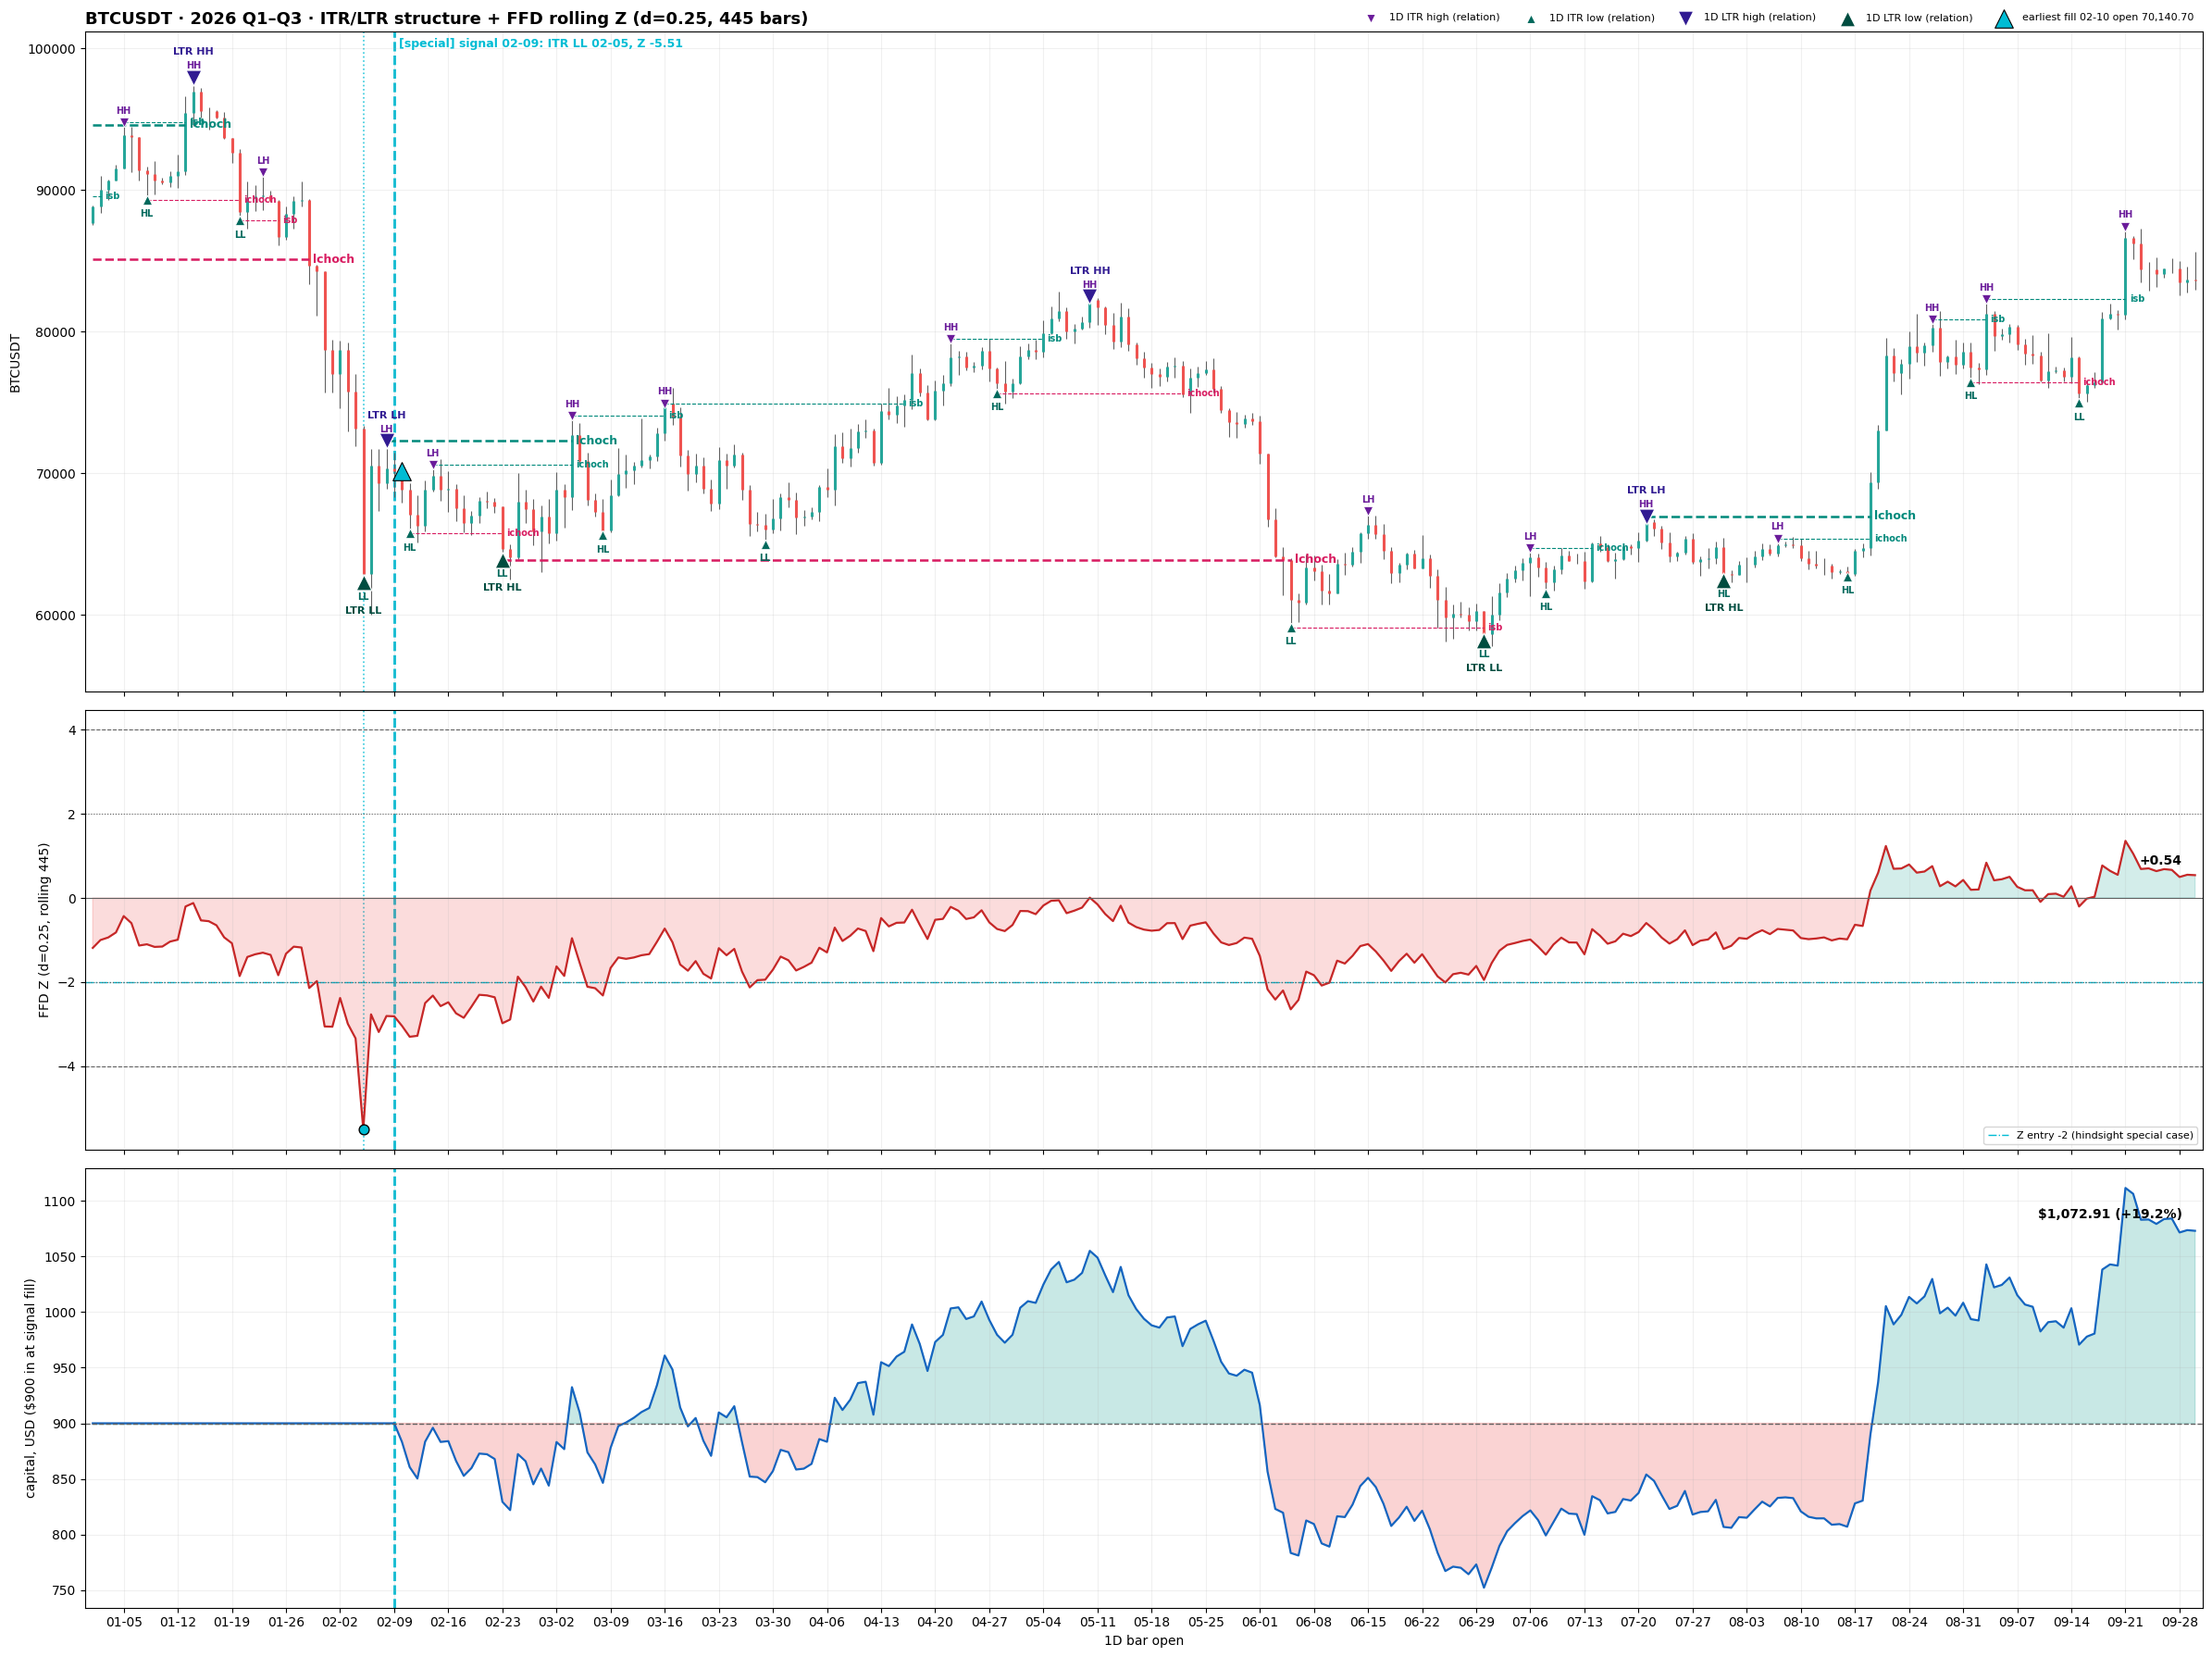

In [6]:
plot_z(bars["BTC"], f"BTCUSDT · {LABEL} · ITR/LTR structure + FFD rolling Z (d={D}, {W} bars)", "BTCUSDT", *struct["BTC"], sig=signals["BTC"], value=capital["BTC"])

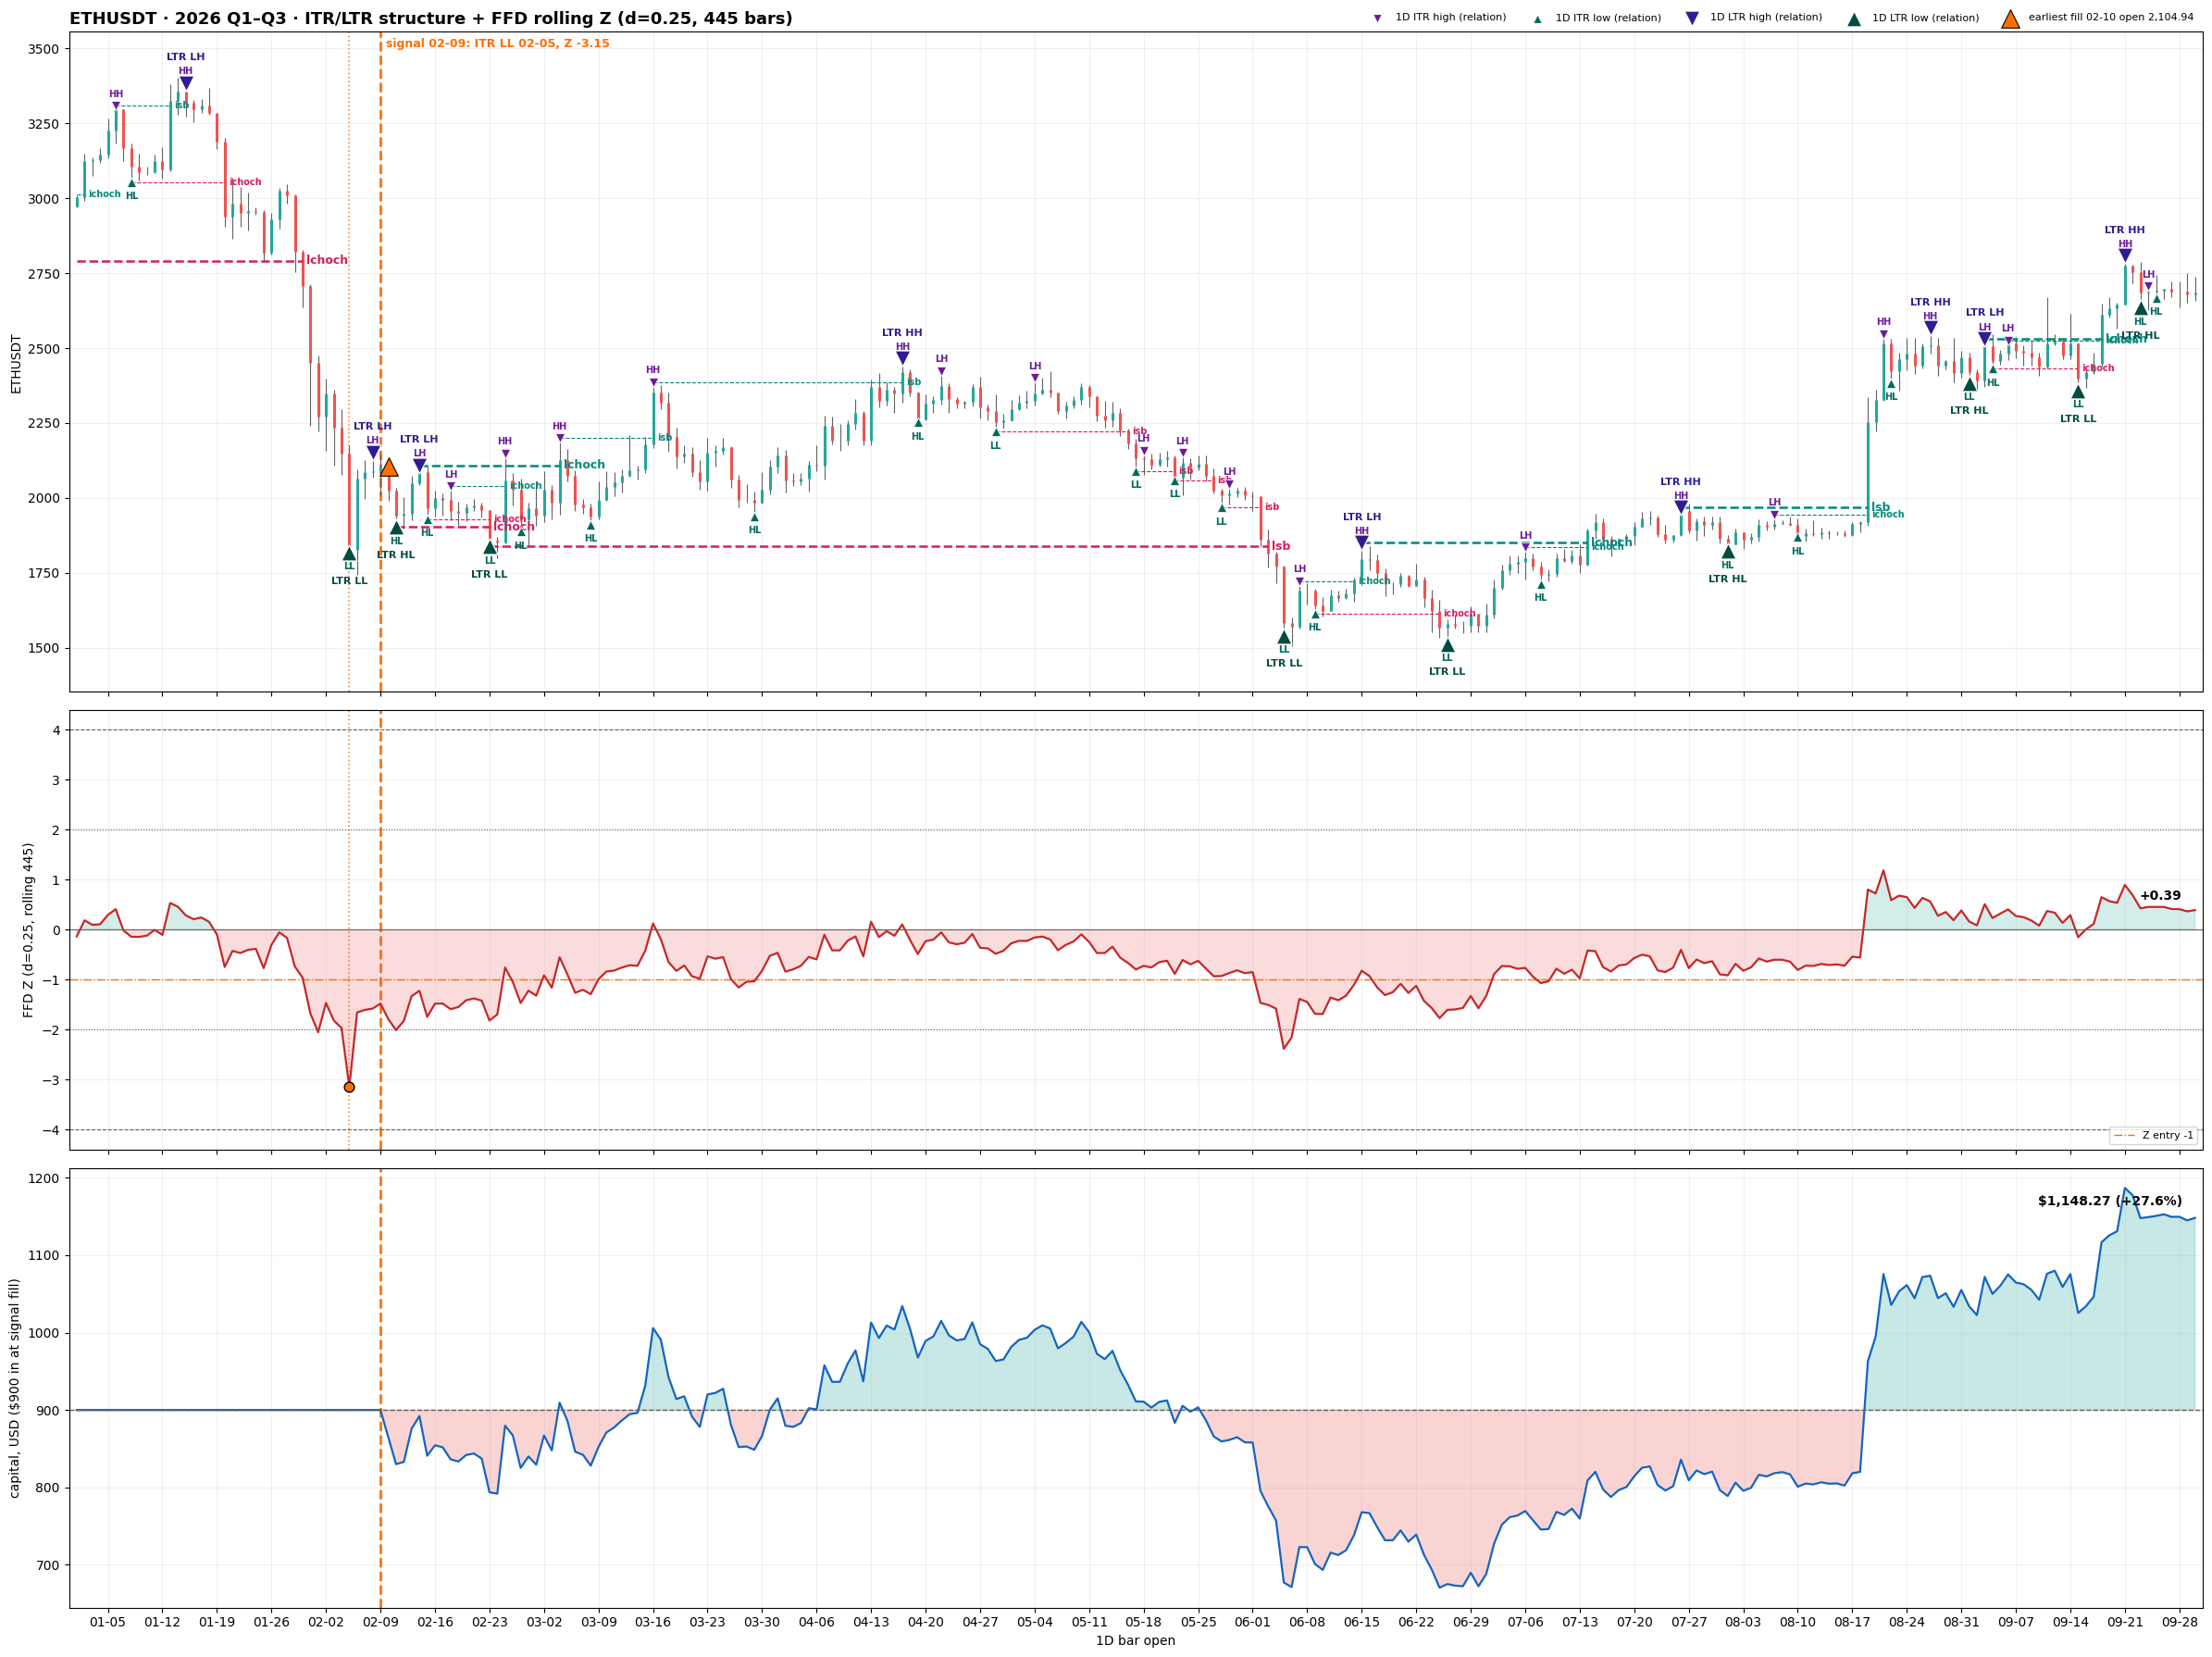

In [7]:
plot_z(bars["ETH"], f"ETHUSDT · {LABEL} · ITR/LTR structure + FFD rolling Z (d={D}, {W} bars)", "ETHUSDT", *struct["ETH"], sig=signals["ETH"], value=capital["ETH"])

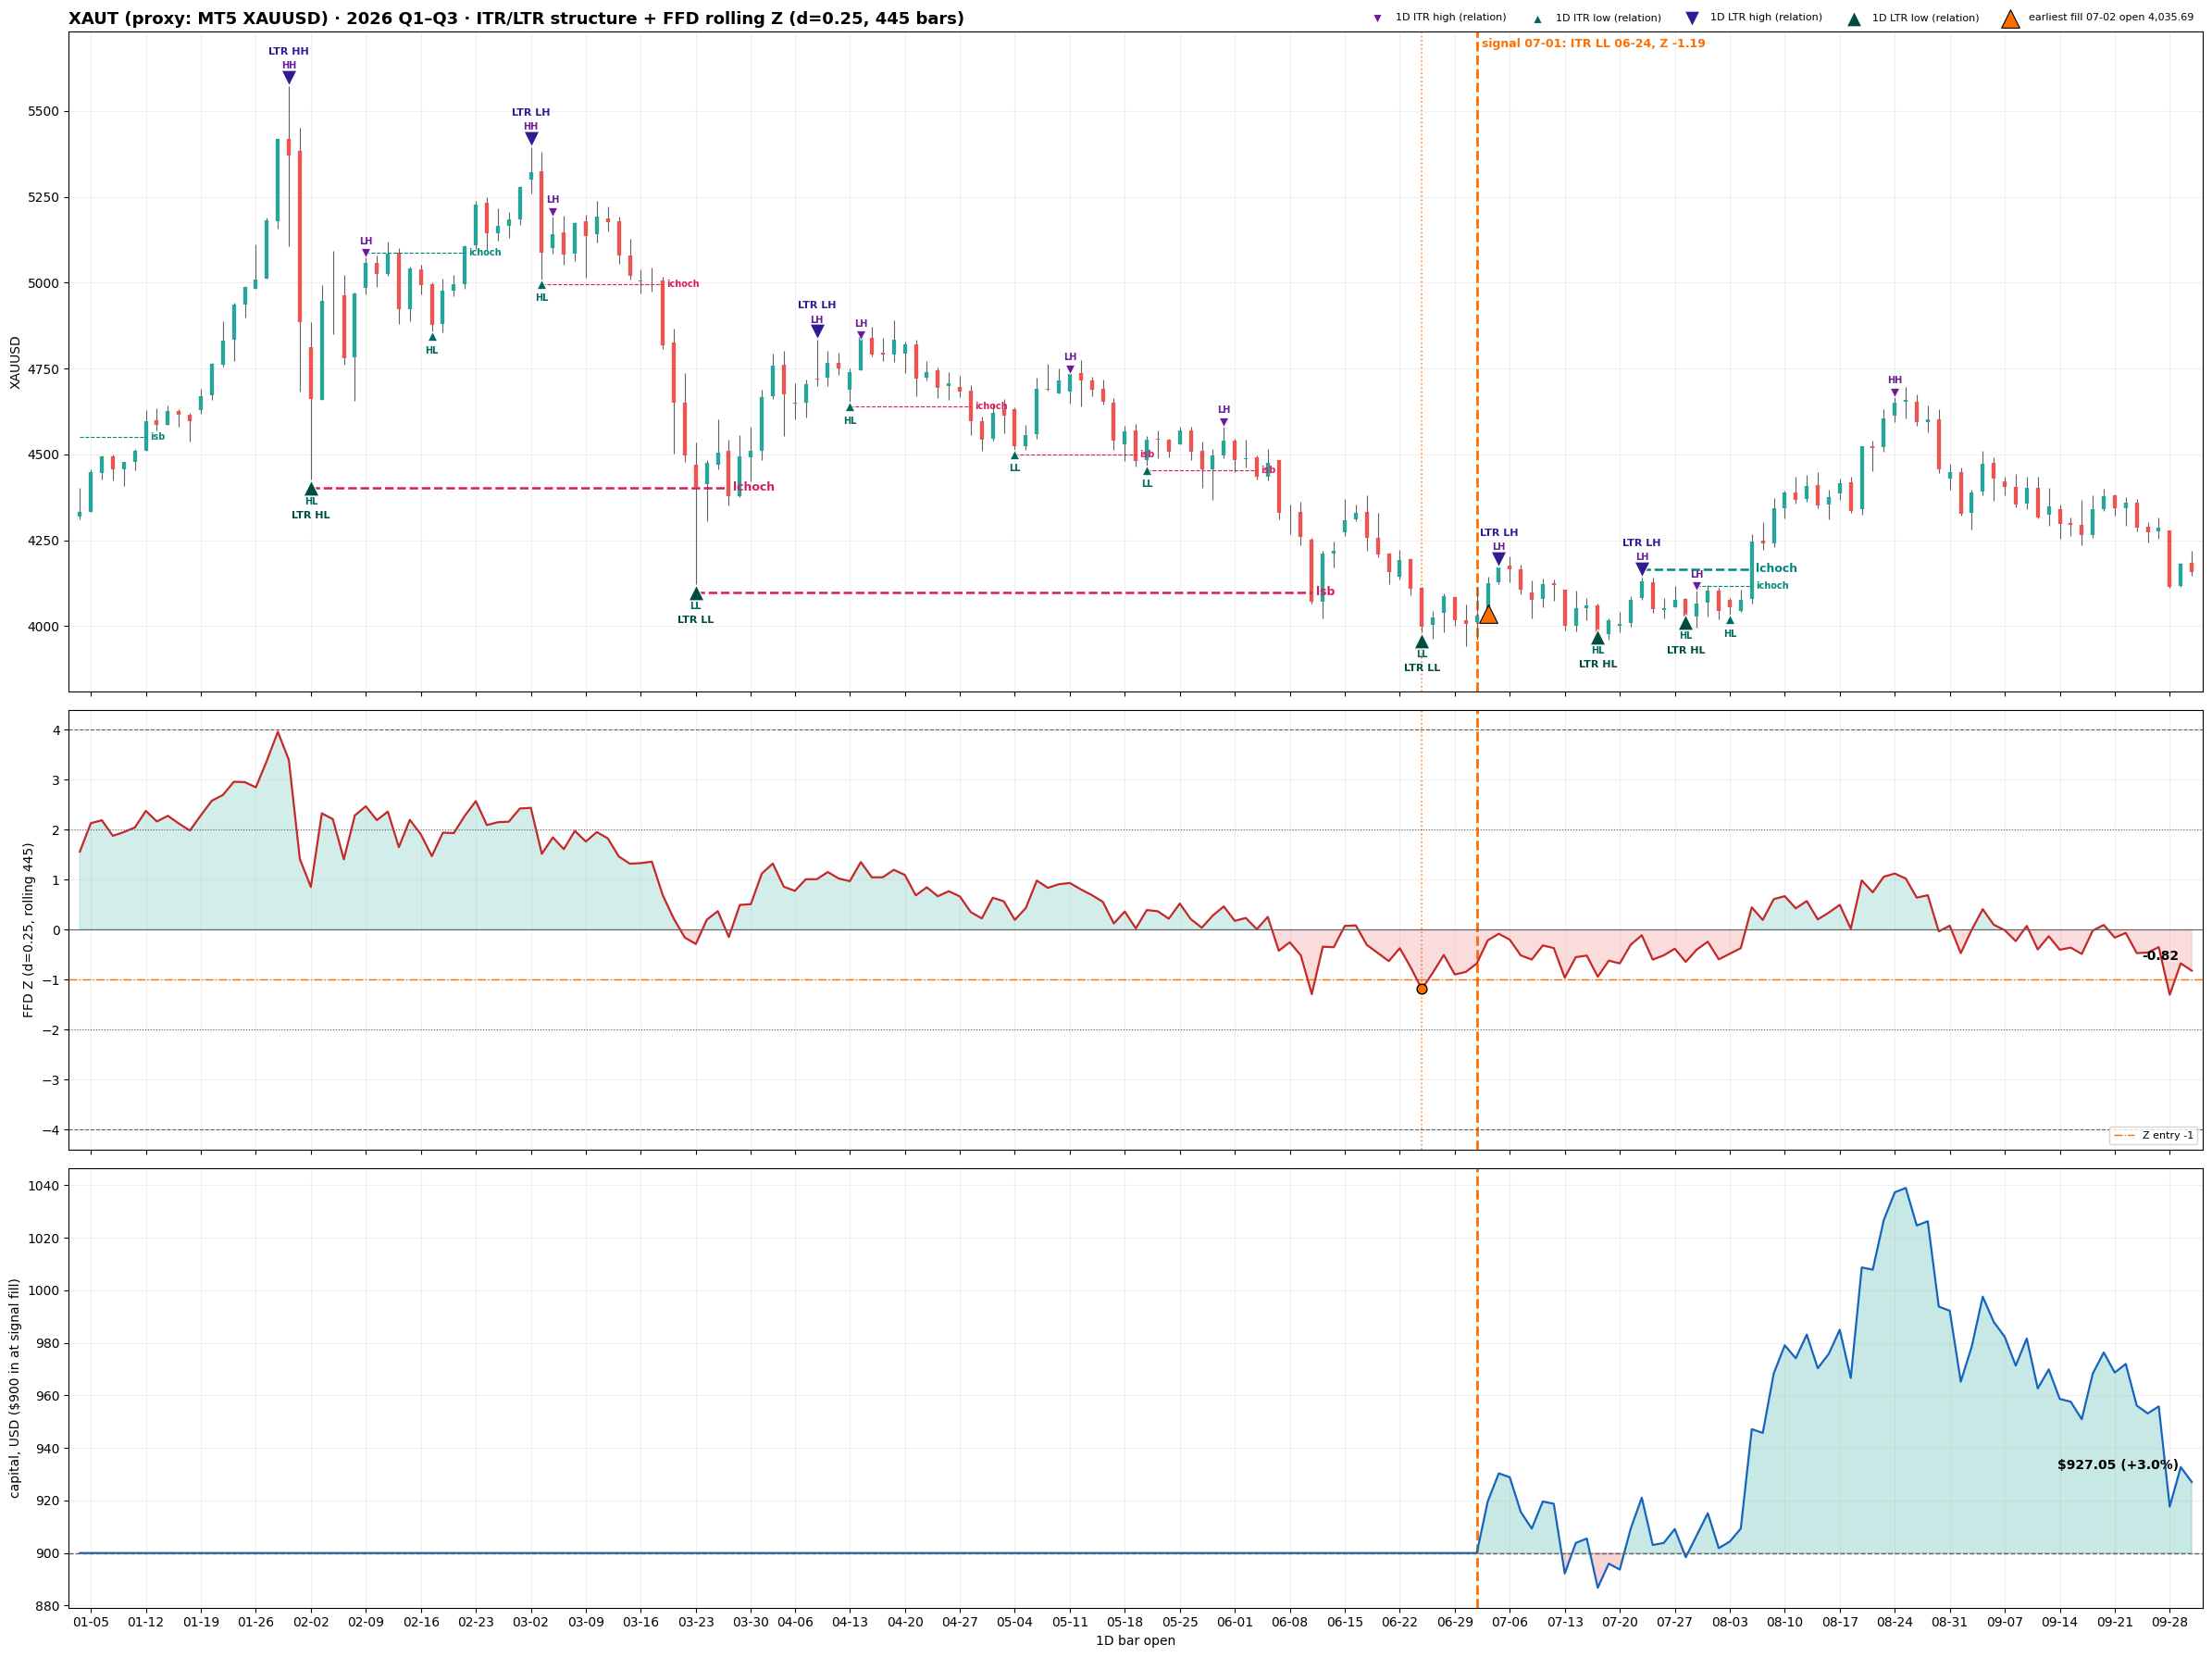

In [8]:
plot_z(bars["XAUT"], f"XAUT (proxy: MT5 XAUUSD) · {LABEL} · ITR/LTR structure + FFD rolling Z (d={D}, {W} bars)", "XAUUSD", *struct["XAUT"], sig=signals["XAUT"], value=capital["XAUT"])

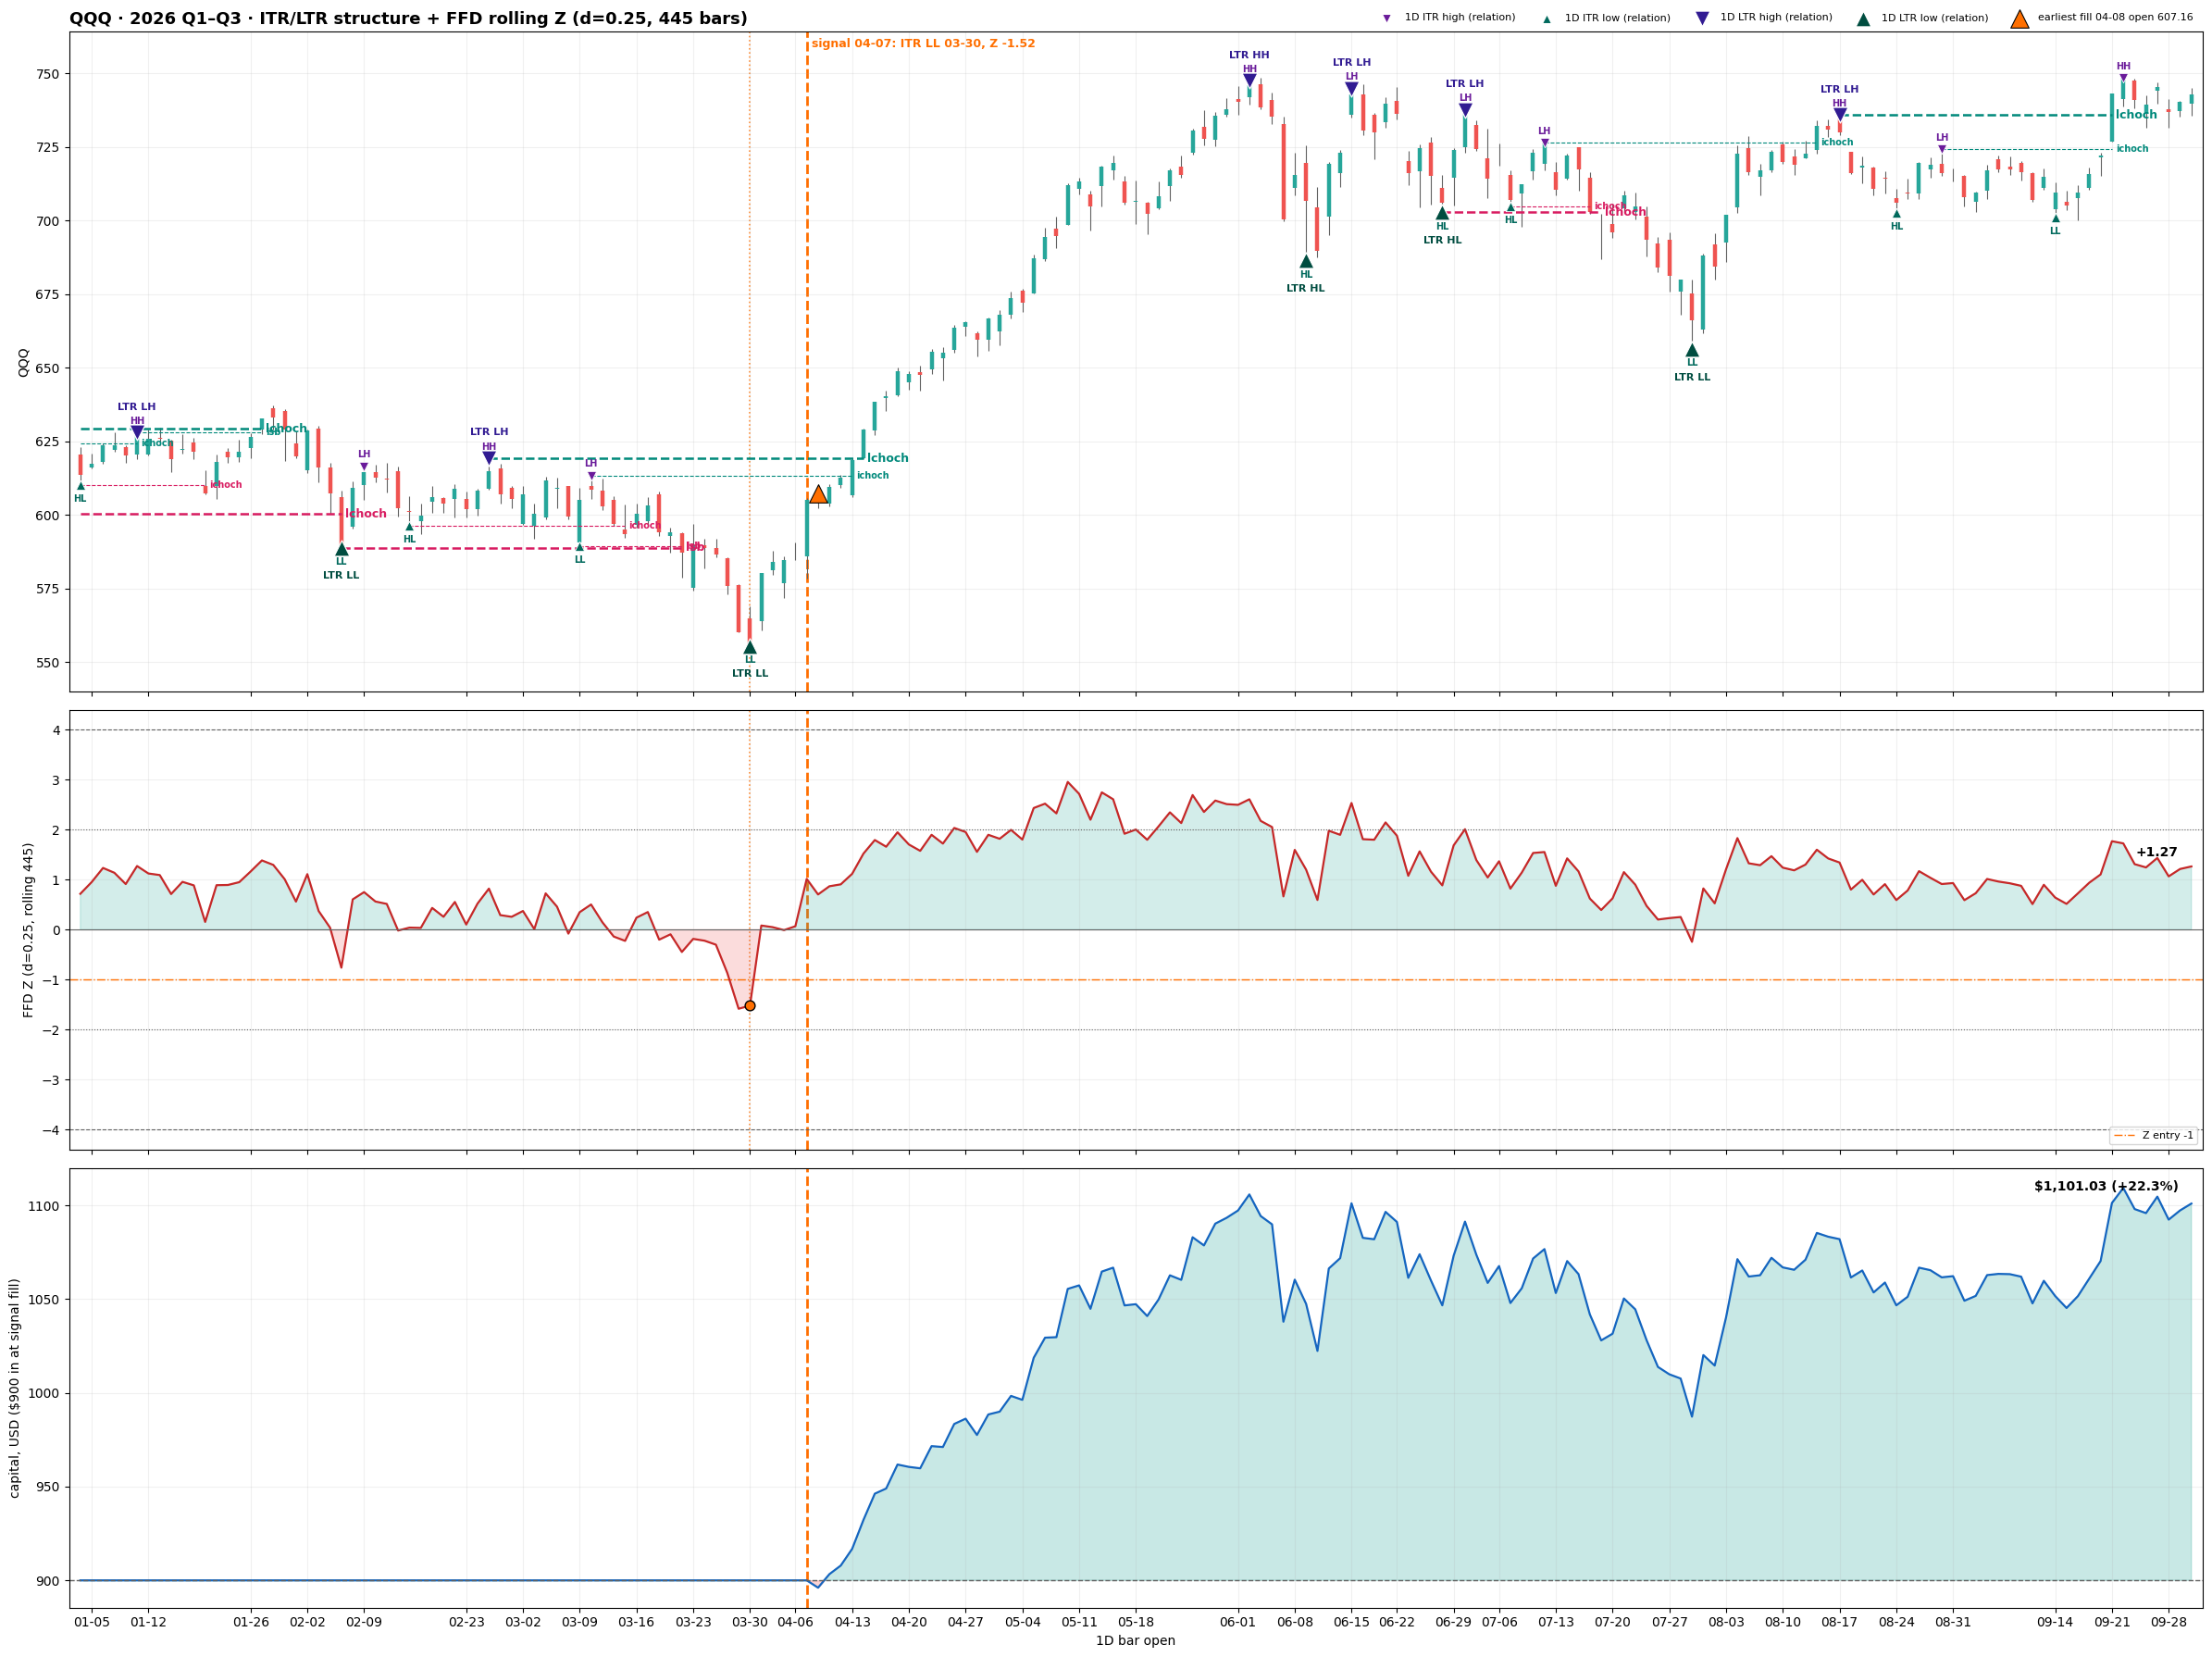

In [9]:
plot_z(bars["QQQ"], f"QQQ · {LABEL} · ITR/LTR structure + FFD rolling Z (d={D}, {W} bars)", "QQQ", *struct["QQQ"], sig=signals["QQQ"], value=capital["QQQ"])